# PCD_Assignment03
**Name:** Rameyza Charisa Putri Primantoko

**NIM:** 25/569972/PA/24024

Assignment 03: Image Segmentation and Morphological Processing

In [39]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from google.colab import files

In [41]:
uploaded = files.upload()

filename = next(iter(uploaded))
print("Uploaded file:", filename)

Saving coinss.jpg to coinss (1).jpg
Uploaded file: coinss (1).jpg


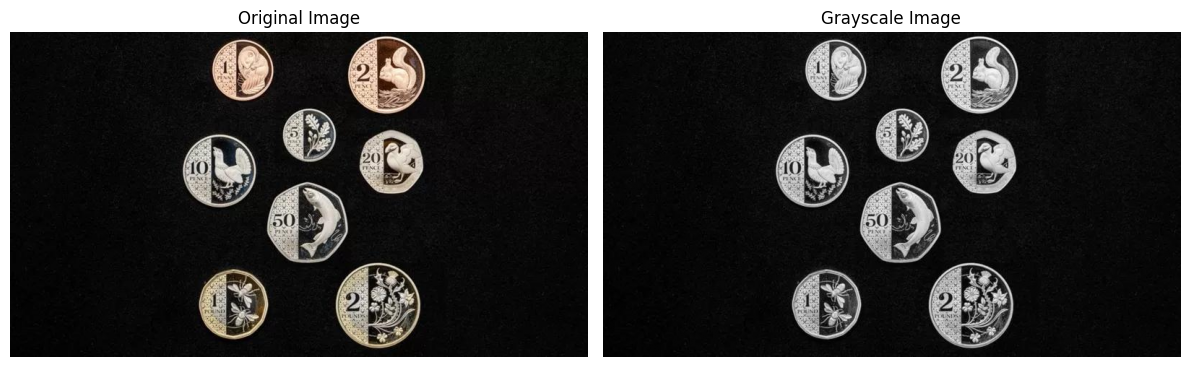

In [42]:

image = Image.open(filename).convert("RGB")

original = np.array(image)
gray = np.array(image.convert("L"))

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(gray, cmap="gray", vmin=0, vmax=255)
plt.title("Grayscale Image")
plt.axis("off")

plt.tight_layout()
plt.show()


In [43]:

def otsu_threshold(gray):
    histogram = np.zeros(256, dtype=int)

    for pixel in gray.flat:
        histogram[int(pixel)] += 1

    total = gray.size
    total_sum = 0

    for i in range(256):
        total_sum += i * histogram[i]

    background_weight = 0
    background_sum = 0
    max_variance = -1
    best_threshold = 0

    for t in range(256):
        background_weight += histogram[t]

        if background_weight == 0:
            continue

        foreground_weight = total - background_weight

        if foreground_weight == 0:
            break

        background_sum += t * histogram[t]

        mean_background = background_sum / background_weight
        mean_foreground = (
            (total_sum - background_sum) / foreground_weight
        )

        variance = (
            background_weight * foreground_weight *
            (mean_background - mean_foreground) ** 2
        )

        if variance > max_variance:
            max_variance = variance
            best_threshold = t

    return best_threshold


threshold = otsu_threshold(gray)
print("Otsu Threshold:", threshold)


Otsu Threshold: 96


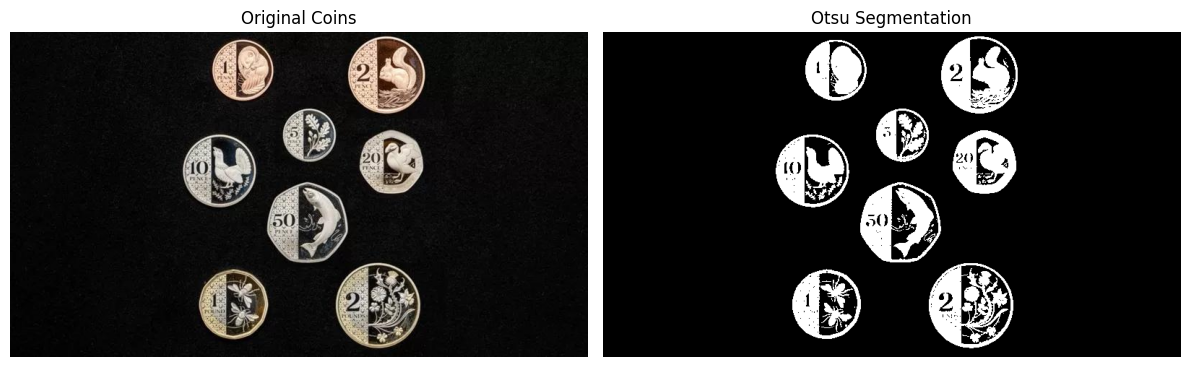

In [44]:

binary = np.zeros(gray.shape, dtype=np.uint8)

for y in range(gray.shape[0]):
    for x in range(gray.shape[1]):
        if gray[y, x] > threshold:
            binary[y, x] = 1
        else:
            binary[y, x] = 0

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original)
plt.title("Original Coins")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(binary, cmap="gray", vmin=0, vmax=1)
plt.title("Otsu Segmentation")
plt.axis("off")

plt.tight_layout()
plt.show()


In [45]:

kernel = np.ones((3, 3), dtype=np.uint8)

print("Structuring Element:")
print(kernel)


def dilation(image, kernel):
    height, width = image.shape
    kh, kw = kernel.shape

    padded = np.pad(
        image,
        ((kh // 2, kh // 2), (kw // 2, kw // 2)),
        mode="constant"
    )

    result = np.zeros_like(image)

    for y in range(height):
        for x in range(width):
            for i in range(kh):
                for j in range(kw):
                    if kernel[i, j] == 1:
                        if padded[y+i, x+j] == 1:
                            result[y, x] = 1

    return result


def erosion(image, kernel):
    height, width = image.shape
    kh, kw = kernel.shape

    padded = np.pad(
        image,
        ((kh // 2, kh // 2), (kw // 2, kw // 2)),
        mode="constant"
    )

    result = np.zeros_like(image)

    for y in range(height):
        for x in range(width):
            match = True

            for i in range(kh):
                for j in range(kw):
                    if kernel[i, j] == 1:
                        if padded[y+i, x+j] == 0:
                            match = False

            if match:
                result[y, x] = 1

    return result


def opening(image, kernel):
    return dilation(erosion(image, kernel), kernel)


def closing(image, kernel):
    return erosion(dilation(image, kernel), kernel)


dilated = dilation(binary, kernel)
eroded = erosion(binary, kernel)
opened = opening(binary, kernel)
closed = closing(binary, kernel)
opened_closed = closing(opened, kernel)

print("Morphological processing completed!")


Structuring Element:
[[1 1 1]
 [1 1 1]
 [1 1 1]]
Morphological processing completed!


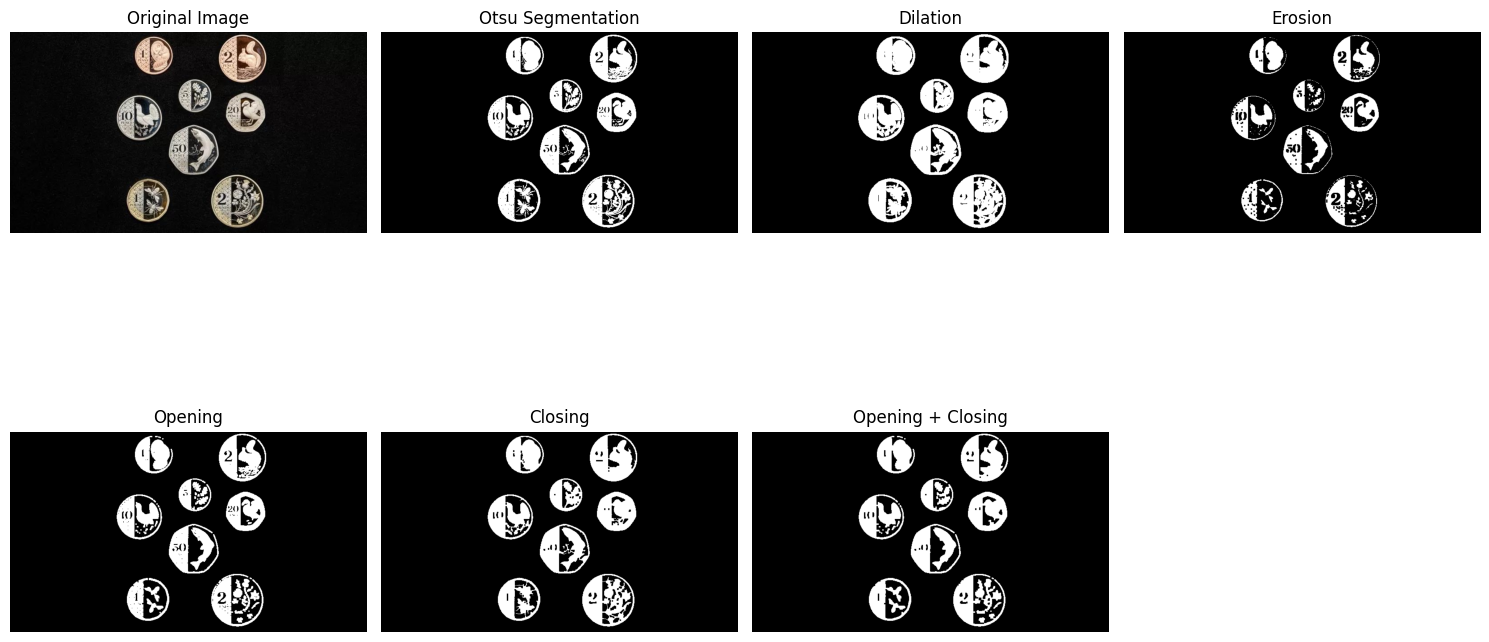

In [46]:

images = [
    original,
    binary,
    dilated,
    eroded,
    opened,
    closed,
    opened_closed
]

titles = [
    "Original Image",
    "Otsu Segmentation",
    "Dilation",
    "Erosion",
    "Opening",
    "Closing",
    "Opening + Closing"
]

plt.figure(figsize=(15, 9))

for i in range(len(images)):
    plt.subplot(2, 4, i + 1)

    if i == 0:
        plt.imshow(images[i])
    else:
        plt.imshow(
            images[i],
            cmap="gray",
            vmin=0,
            vmax=1
        )

    plt.title(titles[i])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [47]:

results = {
    "Otsu Segmentation": binary,
    "Dilation": dilated,
    "Erosion": eroded,
    "Opening": opened,
    "Closing": closed,
    "Opening + Closing": opened_closed
}

original_count = int(np.sum(binary))

print(f"{'Method':<25} {'White Pixels':<15} {'Change'}")
print("-" * 55)

for name, img in results.items():
    count = int(np.sum(img))
    change = count - original_count

    print(f"{name:<25} {count:<15} {change:+}")


Method                    White Pixels    Change
-------------------------------------------------------
Otsu Segmentation         42659           +0
Dilation                  54261           +11602
Erosion                   29975           -12684
Opening                   40654           -2005
Closing                   44945           +2286
Opening + Closing         41772           -887


##Conclusion
In this assignment, Otsu's thresholding was implemented manually to segment coins from a dark background. Four morphological operations were also implemented without using built-in image processing functions.

Dilation expanded the white foreground regions, while erosion reduced their size. Opening was applied to remove small foreground details, and closing was used to fill small gaps within the segmented objects.

The comparison shows that morphological processing can change the shape and structure of segmented objects. The effect of each operation depends on the structuring element and the characteristics of the input image.